In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.metrics import recall_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score,RandomizedSearchCV



from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier
import pickle

In [3]:
df = pd.read_csv('Children_ASD.csv')

In [4]:
df.head()

,Unnamed: 0,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10_Autism_Spectrum_Quotient,Age_Years,Sex,Ethnicity,Jaundice,Family_mem_with_ASD,Who_completed_the_test,ASD_traits
0,0,0,0,0,0,0,0,1,1,0,1,2.0,F,Middle Eastern,Yes,No,Family Member,No
1,1,1,1,0,0,0,1,1,0,0,0,3.0,M,White European,Yes,No,Family Member,Yes
2,2,1,0,0,0,0,0,1,1,0,1,3.0,M,Middle Eastern,Yes,No,Family Member,Yes
3,3,1,1,1,1,1,1,1,1,1,1,2.0,M,Hispanic,No,No,Family Member,Yes
4,4,1,1,0,1,1,1,1,1,1,1,1.0,F,White European,No,Yes,Family Member,Yes


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,2226.0,1112.500000,642.735171,0.0,556.25,1112.5,1668.75,2225.0
A1,2226.0,0.432165,0.495488,0.0,0.00,0.0,1.00,1.0
A2,2226.0,0.345463,0.475626,0.0,0.00,0.0,1.00,1.0
A3,2226.0,0.311321,0.463138,0.0,0.00,0.0,1.00,1.0
A4,2226.0,0.395777,0.489127,0.0,0.00,0.0,1.00,1.0
A5,2226.0,0.403863,0.490781,0.0,0.00,0.0,1.00,1.0
A6,2226.0,0.440252,0.496529,0.0,0.00,0.0,1.00,1.0
A7,2226.0,0.504942,0.500088,0.0,0.00,1.0,1.00,1.0
A8,2226.0,0.356244,0.478996,0.0,0.00,0.0,1.00,1.0
A9,2226.0,0.371518,0.483319,0.0,0.00,0.0,1.00,1.0


In [6]:
df.head(1)

,Unnamed: 0,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10_Autism_Spectrum_Quotient,Age_Years,Sex,Ethnicity,Jaundice,Family_mem_with_ASD,Who_completed_the_test,ASD_traits
0,0,0,0,0,0,0,0,1,1,0,1,2.0,F,Middle Eastern,Yes,No,Family Member,No


In [7]:
df.drop_duplicates(inplace=True)

In [8]:
df.drop(columns=['Ethnicity'], inplace=True)

In [9]:
df.rename(columns={'A10_Autism_Spectrum_Quotient': 'A10'}, inplace=True)

In [10]:
df.rename(columns={'Family_mem_with_ASD': 'history'}, inplace=True) #family history of autism

In [11]:
df.rename(columns={'Who_completed_the_test': 'Completed_By'}, inplace=True)#form filled by who
df.head()

,Unnamed: 0,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,Age_Years,Sex,Jaundice,history,Completed_By,ASD_traits
0,0,0,0,0,0,0,0,1,1,0,1,2.0,F,Yes,No,Family Member,No
1,1,1,1,0,0,0,1,1,0,0,0,3.0,M,Yes,No,Family Member,Yes
2,2,1,0,0,0,0,0,1,1,0,1,3.0,M,Yes,No,Family Member,Yes
3,3,1,1,1,1,1,1,1,1,1,1,2.0,M,No,No,Family Member,Yes
4,4,1,1,0,1,1,1,1,1,1,1,1.0,F,No,Yes,Family Member,Yes


In [12]:
df.rename(columns={'Sex': 'gender'}, inplace=True)
df.rename(columns={'Unnamed: 0': 'id'}, inplace=True)
df.rename(columns={'Age_Years': 'Age'}, inplace=True)
df.rename(columns={'ASD_traits': 'ASD'}, inplace=True)
df.head()

,id,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,Age,gender,Jaundice,history,Completed_By,ASD
0,0,0,0,0,0,0,0,1,1,0,1,2.0,F,Yes,No,Family Member,No
1,1,1,1,0,0,0,1,1,0,0,0,3.0,M,Yes,No,Family Member,Yes
2,2,1,0,0,0,0,0,1,1,0,1,3.0,M,Yes,No,Family Member,Yes
3,3,1,1,1,1,1,1,1,1,1,1,2.0,M,No,No,Family Member,Yes
4,4,1,1,0,1,1,1,1,1,1,1,1.0,F,No,Yes,Family Member,Yes


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2226 entries, 0 to 2225
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            2226 non-null   int64  
 1   A1            2226 non-null   int64  
 2   A2            2226 non-null   int64  
 3   A3            2226 non-null   int64  
 4   A4            2226 non-null   int64  
 5   A5            2226 non-null   int64  
 6   A6            2226 non-null   int64  
 7   A7            2226 non-null   int64  
 8   A8            2226 non-null   int64  
 9   A9            2226 non-null   int64  
 10  A10           2226 non-null   int64  
 11  Age           2226 non-null   float64
 12  gender        2226 non-null   str    
 13  Jaundice      2226 non-null   str    
 14  history       2226 non-null   str    
 15  Completed_By  2226 non-null   str    
 16  ASD           2226 non-null   str    
dtypes: float64(1), int64(11), str(5)
memory usage: 295.8 KB


In [14]:
print(df['gender'].value_counts())
print(df['gender'].unique())
print(df['history'].value_counts()) 
print(df['history'].unique())

gender
M    1610
F     616
Name: count, dtype: int64
<StringArray>
['F', 'M']
Length: 2, dtype: str
history
No     1649
Yes     577
Name: count, dtype: int64
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [15]:
print(df['Completed_By'].value_counts())
print(df['Completed_By'].unique())  
print(df['ASD'].value_counts()) 
print(df['ASD'].unique())


Completed_By
Family Member               1483
Health Care Professional     719
School and NGO                14
Self                           7
Others                         3
Name: count, dtype: int64
<StringArray>
['Family Member', 'Health Care Professional', 'Self', 'Others',
 'School and NGO']
Length: 5, dtype: str
ASD
Yes    1372
No      854
Name: count, dtype: int64
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [16]:
object_cols = df.select_dtypes(include=['object']).columns

C:\Users\sumia\AppData\Local\Temp\ipykernel_9528\737766966.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include=['object']).columns


In [17]:
print(object_cols)

Index(['gender', 'Jaundice', 'history', 'Completed_By', 'ASD'], dtype='str')


In [18]:
encoders ={}
for column in object_cols:
    label_encoder = LabelEncoder()
    df[column] = label_encoder.fit_transform(df[column])
    encoders[column] = label_encoder

    with open ('encoders1.pkl', 'wb') as f:
        pickle.dump(encoders, f)

In [19]:
df.head()

,id,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,Age,gender,Jaundice,history,Completed_By,ASD
0,0,0,0,0,0,0,0,1,1,0,1,2.0,0,1,0,0,0
1,1,1,1,0,0,0,1,1,0,0,0,3.0,1,1,0,0,1
2,2,1,0,0,0,0,0,1,1,0,1,3.0,1,1,0,0,1
3,3,1,1,1,1,1,1,1,1,1,1,2.0,1,0,0,0,1
4,4,1,1,0,1,1,1,1,1,1,1,1.0,0,0,1,0,1


In [20]:

print(df['Completed_By'].unique())
print(df['Completed_By'].value_counts())

[0 1 4 2 3]
Completed_By
0    1483
1     719
3      14
4       7
2       3
Name: count, dtype: int64


In [21]:
encoders

{'gender': LabelEncoder(),
 'Jaundice': LabelEncoder(),
 'history': LabelEncoder(),
 'Completed_By': LabelEncoder(),
 'ASD': LabelEncoder()}

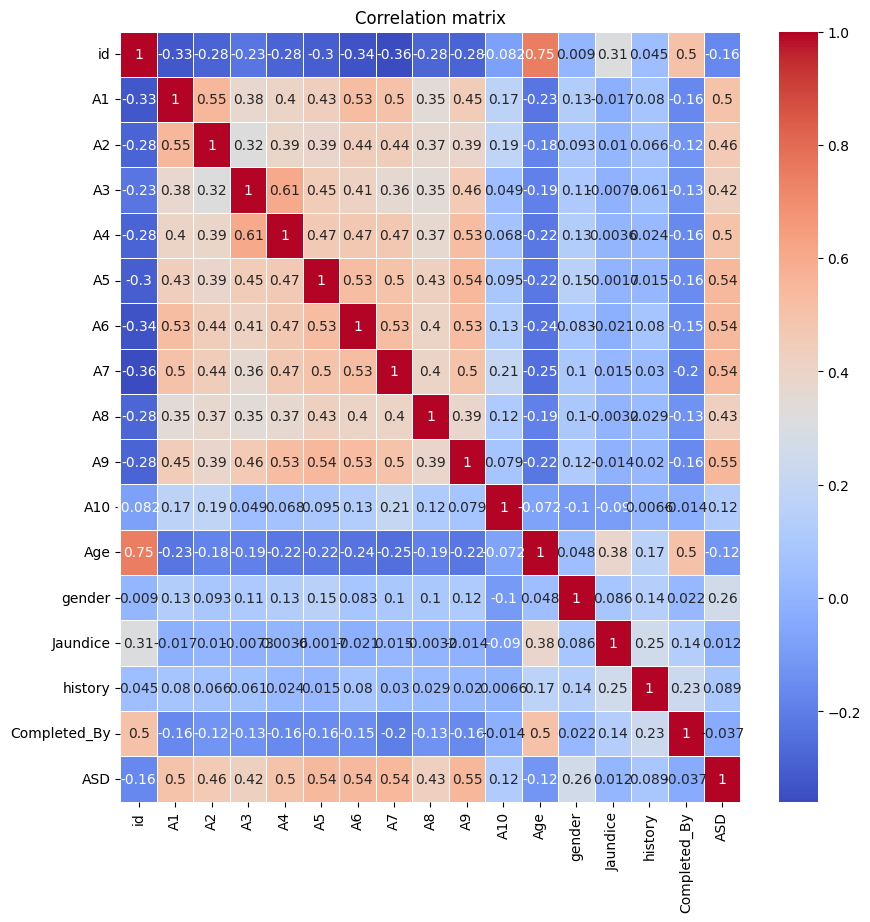

In [22]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation matrix')   
plt.show()

In [23]:
x = df[['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10']]#features
y = df['ASD']#target

In [24]:
print(x)

      A1  A2  A3  A4  A5  A6  A7  A8  A9  A10
0      0   0   0   0   0   0   1   1   0    1
1      1   1   0   0   0   1   1   0   0    0
2      1   0   0   0   0   0   1   1   0    1
3      1   1   1   1   1   1   1   1   1    1
4      1   1   0   1   1   1   1   1   1    1
...   ..  ..  ..  ..  ..  ..  ..  ..  ..  ...
2221   0   0   0   0   0   0   0   0   0    1
2222   0   0   0   0   0   0   0   0   0    1
2223   0   0   0   0   0   0   0   0   0    1
2224   0   0   0   0   0   0   0   0   0    1
2225   0   0   0   0   0   0   0   0   0    1

[2226 rows x 10 columns]


In [25]:
print(y)

0       0
1       1
2       1
3       1
4       1
       ..
2221    0
2222    0
2223    0
2224    1
2225    1
Name: ASD, Length: 2226, dtype: int64


In [26]:
x_train ,x_test ,y_train ,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [27]:
#model train 
smote = SMOTE(random_state=42) 

In [28]:
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

In [29]:
#list of classiiers
models ={
    "Decision Tree":DecisionTreeClassifier(random_state=42),
     "Random forest":RandomForestClassifier(random_state=42),
     "XGBoost":XGBClassifier(random_state=42)   
}

In [30]:
print(models)

{'Decision Tree': DecisionTreeClassifier(random_state=42), 'Random forest': RandomForestClassifier(random_state=42), 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)}


In [31]:
#dictionary to stor the cross validation results
cv_scores ={}
#   perform 5-fold cross validation for each model and store the results
for model_name, model in models.items():
    print(f"Training {model_name} with default parameters...")
    scores = cross_val_score(model, x_train_smote, y_train_smote, cv=5, scoring="accuracy")
    cv_scores[model_name] = scores
    print(f"{model_name} Cross-validation accuracy: {np.mean(scores):.2f}")
    print("-"*50)

Training Decision Tree with default parameters...
Decision Tree Cross-validation accuracy: 0.91
--------------------------------------------------
Training Random forest with default parameters...
Random forest Cross-validation accuracy: 0.92
--------------------------------------------------
Training XGBoost with default parameters...
XGBoost Cross-validation accuracy: 0.92
--------------------------------------------------


In [32]:
cv_scores

{'Decision Tree': array([0.91136364, 0.90454545, 0.92272727, 0.91571754, 0.90888383]),
 'Random forest': array([0.91136364, 0.91818182, 0.925     , 0.91799544, 0.91116173]),
 'XGBoost': array([0.925     , 0.91363636, 0.93636364, 0.91799544, 0.91116173])}

In [33]:
#model selection and hyper parameter tuning
#initialing model
decision_tree =DecisionTreeClassifier(random_state=42)  
random_forest = RandomForestClassifier(random_state=42)
XGBClassifier = XGBClassifier(random_state=42)

In [34]:
#hyperparameter grids for randomized searchcv
param_grid_dt ={
    "criterion":["gini", "entropy"],
    "max_depth":[None, 10,20,30,50,70],
    "min_samples_split":[2, 5, 10],
     "min_samples_leaf":[1, 2, 4]
}

param_grid_rf = {
    "n_estimators":[50,100,200,500],
    "max_depth":[None, 10,20,30],
    "min_samples_split":[2, 5, 10],
     "min_samples_leaf":[1, 2, 4],
     "bootstrap":[True, False]       
}

param_grid_xgb ={
    "n_estimators":[50,100,200,500],
    "max_depth":[3, 5, 7, 10],
    "learning_rate":[0.01, 0.1, 0.2, 0.3],
    "subsample":[0.5, 0.7, 1.0],
     "colsample_bytree":[0.5, 0.7, 1.0] 
}


In [35]:
#tuning for 3 tree based models and below steps wllbe automated by using a for loop or by using a pipeline perform randomized searchcv for each model
#perform randomized seacch cv for each model 
random_search_dt = RandomizedSearchCV(estimator=decision_tree, param_distributions=param_grid_dt, n_iter=10, cv=5, scoring="accuracy", random_state=42)
random_search_rf = RandomizedSearchCV(estimator=random_forest, param_distributions=param_grid_rf, n_iter=10, cv=5, scoring="accuracy", random_state=42)
random_search_xgb = RandomizedSearchCV(estimator=XGBClassifier, param_distributions=  param_grid_xgb, n_iter=10, cv=5, scoring="accuracy", random_state=42)

In [36]:
#fiting model
random_search_dt.fit(x_train_smote, y_train_smote)
random_search_rf.fit(x_train_smote, y_train_smote)
random_search_xgb.fit(x_train_smote, y_train_smote)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.5, 0.7, ...], 'learning_rate': [0.01, 0.1, ...], 'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be u

In [37]:
print(random_search_dt.best_estimator_)
print (random_search_dt.best_score_)

print(random_search_rf.best_estimator_)
print(random_search_rf.best_score_)

print(random_search_xgb.best_estimator_)
print(random_search_xgb.best_score_) 

DecisionTreeClassifier(max_depth=70, random_state=42)
0.9126475460757921
RandomForestClassifier(max_depth=20, min_samples_split=5, random_state=42)
0.9162859805342721
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.5, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.2, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=None, num_parallel_tree=None, ...)
0.926742596810934


In [38]:
#get the model with best score
best_model = None 
best_score =0

if random_search_dt.best_score_ >best_score:
    best_model = random_search_dt.best_estimator_
    best_score = random_search_dt.best_score_

if random_search_rf.best_score_ >best_score:
    best_model = random_search_rf.best_estimator_
    best_score = random_search_rf.best_score_  
       
if random_search_xgb.best_score_ >best_score:
    best_model = random_search_xgb.best_estimator_
    best_score = random_search_xgb.best_score_       
print(f"Best model: {best_model}")
print(f"Best cross-validation accuracy: {best_score:.2f}")

Best model: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.5, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.2, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=None, num_parallel_tree=None, ...)
Best cross-validation accuracy: 0.93


In [39]:
#evaluate the best model on the test set
y_test_pred = best_model.predict(x_test)
print("Accuracy Score:\n",accuracy_score(y_test,y_test_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test,y_test_pred))
print("Classification Report:\n", classification_report(y_test, y_test_pred))

Accuracy Score:
 0.9237668161434978
Confusion Matrix:
 [[173   0]
 [ 34 239]]
Classification Report:
               precision    recall  f1-score   support

           0       0.84      1.00      0.91       173
           1       1.00      0.88      0.93       273

    accuracy                           0.92       446
   macro avg       0.92      0.94      0.92       446
weighted avg       0.94      0.92      0.92       446



In [40]:
# Pickle (iincluding threshold and preprocessing )
import pickle
pickle.dump(model, open("asd_model.pkl", "wb"))

In [41]:
from xgboost import XGBClassifier
model = XGBClassifier(
    scale_pos_weight=2.5,  # Adjust to boost ASD recall
    n_estimators=500,
    max_depth=5,
    learning_rate=0.2,
    colsample_bytree=0.5,
    use_label_encoder=False,
    eval_metric='logloss'
)
model.fit(x_train, y_train)


C:\Users\sumia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\xgboost\training.py:200: UserWarning: [13:09:49] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.5
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

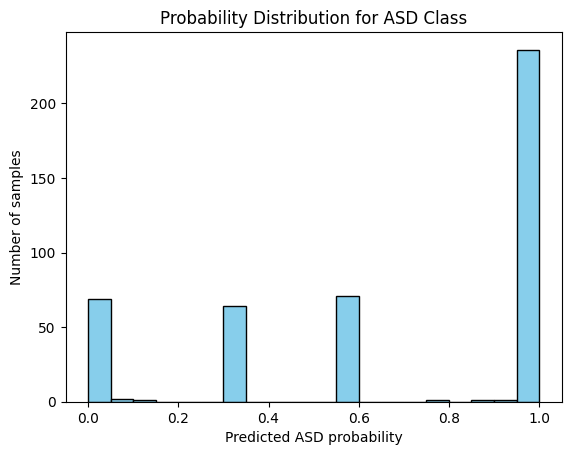

In [42]:
probs = model.predict_proba(x_test)[:,1]

# -----------------------------
# 4. Visualize probability distribution (optional, useful!)
# -----------------------------
plt.hist(probs, bins=20, color='skyblue', edgecolor='black')
plt.xlabel("Predicted ASD probability")
plt.ylabel("Number of samples")
plt.title("Probability Distribution for ASD Class")
plt.show()

In [43]:
def map_level(p):
    if p <= 0.35:
        return "Low Likelihood"
    elif p <= 0.6:
        return "Medium Likelihood"
    else:
        return "High Likelihood"

levels = [map_level(p) for p in probs]

# Optional: assign colors for visualization
colors = ['Green' if l=="Low Likelihood" else 'Orange' if l=="Medium Likelihood" else 'Red' for l in levels]

In [44]:
# best threshold
best_thresh = 0.0
best_bal_acc = 0.0

thresholds = sorted(list(set(probs)))  # use actual probability spikes
for t in thresholds:
    y_pred = [1 if p >= t else 0 for p in probs]
    r0 = recall_score(y_test, y_pred, pos_label=0)
    r1 = recall_score(y_test, y_pred, pos_label=1)
    bal_acc = (r0 + r1)/2
    if bal_acc > best_bal_acc:
        best_bal_acc = bal_acc
        best_thresh = t

print(f"✅ Best Threshold Found: {best_thresh:.2f} with Balanced Accuracy: {best_bal_acc:.3f}")

✅ Best Threshold Found: 0.77 with Balanced Accuracy: 0.938


In [45]:
# threshold for final binary predicti
y_pred_final = [1 if p >= best_thresh else 0 for p in probs]

print("--- Final Balanced Classification Report ---")
print(classification_report(y_test, y_pred_final, zero_division=0))

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_final))


--- Final Balanced Classification Report ---
              precision    recall  f1-score   support

           0       0.84      1.00      0.91       173
           1       1.00      0.88      0.93       273

    accuracy                           0.92       446
   macro avg       0.92      0.94      0.92       446
weighted avg       0.94      0.92      0.92       446

Confusion Matrix:
 [[173   0]
 [ 34 239]]


In [46]:

final_levels = [map_level(p) for p in probs]
for i in range(10):  # show first 10 samples
    print(f"Sample {i+1}: Prob={probs[i]:.2f}, Level={final_levels[i]}, Binary={y_pred_final[i]}")

Sample 1: Prob=1.00, Level=High Likelihood, Binary=1
Sample 2: Prob=1.00, Level=High Likelihood, Binary=1
Sample 3: Prob=0.60, Level=Medium Likelihood, Binary=0
Sample 4: Prob=1.00, Level=High Likelihood, Binary=1
Sample 5: Prob=1.00, Level=High Likelihood, Binary=1
Sample 6: Prob=1.00, Level=High Likelihood, Binary=1
Sample 7: Prob=1.00, Level=High Likelihood, Binary=1
Sample 8: Prob=0.00, Level=Low Likelihood, Binary=0
Sample 9: Prob=1.00, Level=High Likelihood, Binary=1
Sample 10: Prob=1.00, Level=High Likelihood, Binary=1


In [47]:
    
model.save_model("asd_model.json")  # native
import pickle
pickle.dump(model, open("asd_model.pkl", "wb"))  # python pipeline